# Deep Learning-Based Voice Interview Coach

This notebook trains and compares audio-only models for predicting interview-related scores from speech.

Models:
1. Acoustic feature baseline
2. HuBERT/wav2vec2 embedding-only model
3. Proposed fusion model: HuBERT/wav2vec2 embeddings + acoustic features

Targets:
- speaking_skills
- confidence_score
- interview_score
- overall_performance

In [13]:
from pathlib import Path
import sys
import json
import random

import numpy as np
import pandas as pd

import joblib
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr, spearmanr

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import librosa
from tqdm import tqdm
from transformers import AutoFeatureExtractor, AutoModel

# Because this notebook is inside notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

from config import (
    TRAIN_CSV,
    VAL_CSV,
    TEST_CSV,
    ACOUSTIC_FEATURES_CSV,
    TRAIN_EMBEDDINGS,
    VAL_EMBEDDINGS,
    TEST_EMBEDDINGS,
    TARGET_COLUMNS,
    SAMPLE_RATE,
    MAX_AUDIO_SECONDS,
    SSL_MODEL_NAME,
    MODEL_DIR,
    RESULTS_DIR,
    PLOTS_DIR,
    SEED,
    BATCH_SIZE,
    EPOCHS,
    LEARNING_RATE,
    PATIENCE,
    DEVICE,
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Train CSV:", TRAIN_CSV)
print("Acoustic features:", ACOUSTIC_FEATURES_CSV)
print("Targets:", TARGET_COLUMNS)

Project root: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent
Train CSV: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/data/processed/splits/train.csv
Acoustic features: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/data/processed/acoustic_features.csv
Targets: ['speaking_skills', 'confidence_score', 'interview_score', 'overall_performance']


In [4]:
# Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

device = DEVICE if torch.cuda.is_available() and DEVICE == "cuda" else "cpu"
print("Using device:", device)

Using device: cpu


## Load data splits and acoustic features

In [3]:
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

train_df.head()

Train: (1404, 23)
Val: (328, 23)
Test: (279, 23)


,id,file_name,duration,question_id,question,video_quality,user_no,openness,conscientiousness,extraversion,...,interview_score,answer_score,speaking_skills,confidence_score,facial_expression,overall_performance,transcript,gemini_summary,video_path,audio_path
0,1,videos/vid_0001.mp4,long,1,Introduce yourself,High,147,-0.653086,-0.048688,-0.691034,...,-0.922743,-0.802645,-0.769047,-0.361817,-0.816591,-0.456352,"[00:01 - 00:11] Hello everyone, this is Mathur...","1. Overview:\nThe candidate provides a clear, ...",data/raw/Charvisri07__Voice-interview-agent/vi...,data/processed/audio_wav/vid_0001.wav
1,2,videos/vid_0002.mp4,short,1,Introduce yourself,High,82,-0.007390,0.128426,-0.124832,...,-0.173570,-0.132352,-0.561689,-0.174044,-0.304263,-0.193319,[00:00 - 00:05] I'm Darshita Singh from Aligar...,"1. Overview:\nThe candidate, Darshita Sainger,...",data/raw/Charvisri07__Voice-interview-agent/vi...,data/processed/audio_wav/vid_0002.wav
2,3,videos/vid_0003.mp4,medium,1,Introduce yourself,High,103,0.221345,0.280619,0.246076,...,0.184024,0.223401,0.223328,0.600258,0.268485,0.262246,"[00:01 - 00:08] Hello everyone, I am Faizan J....",1. Overview:\nThe candidate provides a direct ...,data/raw/Charvisri07__Voice-interview-agent/vi...,data/processed/audio_wav/vid_0003.wav
3,5,videos/vid_0005.mp4,long,1,Introduce yourself,High,258,-0.803683,-0.548680,-0.777085,...,-1.028743,-0.944125,-1.211701,-0.546533,-0.614527,-0.905753,"[00:01 - 00:05] Hi, my name is Utkarsh Rana an...","1. Overview:\nThe candidate, Utkarsh Rana, pro...",data/raw/Charvisri07__Voice-interview-agent/vi...,data/processed/audio_wav/vid_0005.wav
4,9,videos/vid_0009.mp4,medium,1,Introduce yourself,High,163,0.073870,0.563856,-0.236230,...,0.318594,0.133232,0.251284,-0.042711,0.322955,0.121336,"[00:00 - 00:04] Hello, my name is Rupur Agarwa...","1. Overview:\nThe candidate, Nupur Agarwal, pr...",data/raw/Charvisri07__Voice-interview-agent/vi...,data/processed/audio_wav/vid_0009.wav


In [5]:
# Load acoustic features

if not ACOUSTIC_FEATURES_CSV.exists():
    raise FileNotFoundError(
        f"{ACOUSTIC_FEATURES_CSV} not found. "
        "Run src/extract_acoustic_features.py first."
    )

acoustic_df = pd.read_csv(ACOUSTIC_FEATURES_CSV)

print("Acoustic features:", acoustic_df.shape)
acoustic_df.head()

Acoustic features: (2011, 15)


,duration_sec,energy_mean,energy_std,energy_max,pause_ratio,voiced_ratio,pitch_mean,pitch_std,pitch_min,pitch_max,speaking_rate,split,audio_path,id,user_no
0,43.468812,0.039892,0.029789,0.176686,0.136484,0.863516,207.373072,52.233120,107.487597,551.172353,136.649696,train,data/processed/audio_wav/vid_0001.wav,1,147
1,14.054937,0.033304,0.018936,0.081877,0.063750,0.936250,215.914167,60.054070,97.998859,538.583559,166.489534,train,data/processed/audio_wav/vid_0002.wav,2,82
2,21.395375,0.022898,0.023501,0.141168,0.228244,0.771756,95.934389,11.034585,68.105200,137.793088,151.434597,train,data/processed/audio_wav/vid_0003.wav,3,103
3,57.783938,0.032432,0.026581,0.138536,0.167104,0.832896,132.248342,57.995455,80.991188,587.329536,183.788099,train,data/processed/audio_wav/vid_0005.wav,5,258
4,28.265563,0.031954,0.024705,0.130765,0.232423,0.767577,243.865586,26.163225,171.614350,337.332236,152.836159,train,data/processed/audio_wav/vid_0009.wav,9,163


## Data preprocessing

- Extract acoustic features

In [6]:
ACOUSTIC_COLUMNS = [
    "duration_sec",
    "energy_mean",
    "energy_std",
    "energy_max",
    "pause_ratio",
    "voiced_ratio",
    "pitch_mean",
    "pitch_std",
    "pitch_min",
    "pitch_max",
    "speaking_rate",
]

missing_cols = [col for col in ACOUSTIC_COLUMNS if col not in acoustic_df.columns]
if missing_cols:
    raise KeyError(f"Missing acoustic columns: {missing_cols}")

print("Acoustic feature columns ready.")

Acoustic feature columns ready.


In [7]:
# metric function

def calculate_metrics(y_true, y_pred, target_columns):
    results = {}

    for i, target in enumerate(target_columns):
        true_values = y_true[:, i]
        pred_values = y_pred[:, i]

        mae = mean_absolute_error(true_values, pred_values)
        rmse = np.sqrt(mean_squared_error(true_values, pred_values))
        r2 = r2_score(true_values, pred_values)

        try:
            pearson = pearsonr(true_values, pred_values)[0]
        except Exception:
            pearson = np.nan

        try:
            spearman = spearmanr(true_values, pred_values)[0]
        except Exception:
            spearman = np.nan

        results[target] = {
            "MAE": float(mae),
            "RMSE": float(rmse),
            "Pearson": float(pearson),
            "Spearman": float(spearman),
            "R2": float(r2),
        }

    results["average"] = {
        metric: float(np.nanmean([results[target][metric] for target in target_columns]))
        for metric in ["MAE", "RMSE", "Pearson", "Spearman", "R2"]
    }

    return results


def save_json(data, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=4)


def metrics_to_dataframe(results, model_name):
    rows = []

    for target, values in results.items():
        row = {"model": model_name, "target": target}
        row.update(values)
        rows.append(row)

    return pd.DataFrame(rows)

In [8]:
# merge splits with acoustic features

train_acoustic = train_df.merge(acoustic_df, on="audio_path", how="inner")
val_acoustic = val_df.merge(acoustic_df, on="audio_path", how="inner")
test_acoustic = test_df.merge(acoustic_df, on="audio_path", how="inner")

print("Train merged:", train_acoustic.shape)
print("Val merged:", val_acoustic.shape)
print("Test merged:", test_acoustic.shape)

if len(train_acoustic) == 0 or len(test_acoustic) == 0:
    raise ValueError("Merge failed. Check whether audio_path matches in split CSVs and acoustic_features.csv.")

Train merged: (1404, 37)
Val merged: (328, 37)
Test merged: (279, 37)


## Model training

There are three baselines:
- Acoustic feature baseline
- Embedding-only deep learning Baseline
- Proposed model

In [9]:
X_train_acoustic = train_acoustic[ACOUSTIC_COLUMNS].values
y_train = train_acoustic[TARGET_COLUMNS].values

X_test_acoustic = test_acoustic[ACOUSTIC_COLUMNS].values
y_test = test_acoustic[TARGET_COLUMNS].values

acoustic_baseline = RandomForestRegressor(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1,
)

acoustic_baseline.fit(X_train_acoustic, y_train)

acoustic_predictions = acoustic_baseline.predict(X_test_acoustic)

acoustic_results = calculate_metrics(
    y_true=y_test,
    y_pred=acoustic_predictions,
    target_columns=TARGET_COLUMNS,
)

joblib.dump(acoustic_baseline, MODEL_DIR / "acoustic_baseline_random_forest.joblib")
save_json(acoustic_results, RESULTS_DIR / "acoustic_baseline_results.json")

pd.DataFrame(acoustic_results).T

,MAE,RMSE,Pearson,Spearman,R2
speaking_skills,0.759961,1.052511,0.358935,0.424025,0.047238
confidence_score,0.726058,1.086812,0.374343,0.406188,0.124302
interview_score,0.780467,1.228388,0.357252,0.431450,0.110627
overall_performance,0.713306,1.035856,0.423995,0.474735,0.159971
average,0.744948,1.100892,0.378631,0.434099,0.110535


In [15]:
# audio path for embedding extraction

def resolve_audio_path(audio_path_value):
    audio_path = Path(str(audio_path_value))

    if audio_path.is_absolute():
        return audio_path

    return PROJECT_ROOT / audio_path


def load_audio_for_ssl(audio_path):
    y, sr = librosa.load(str(audio_path), sr=SAMPLE_RATE, mono=True)

    max_len = SAMPLE_RATE * MAX_AUDIO_SECONDS

    if len(y) > max_len:
        y = y[:max_len]

    return y

In [17]:
# Extract or load SSL embeddings
@torch.no_grad()
def extract_one_embedding(audio_path, feature_extractor, model, device):
    audio = load_audio_for_ssl(audio_path)

    inputs = feature_extractor(
        audio,
        sampling_rate=SAMPLE_RATE,
        return_tensors="pt",
        padding=True,
    )

    input_values = inputs.input_values.to(device)

    outputs = model(input_values)
    hidden_states = outputs.last_hidden_state

    embedding = hidden_states.mean(dim=1).squeeze(0).cpu().numpy()

    return embedding


def extract_embeddings_for_split(split_df, output_path, feature_extractor, model, device):
    embeddings = []
    targets = []
    audio_paths = []

    for _, row in tqdm(split_df.iterrows(), total=len(split_df)):
        audio_path_csv = row["audio_path"]
        audio_path = resolve_audio_path(audio_path_csv)

        if not audio_path.exists():
            print("Missing audio:", audio_path)
            continue

        try:
            embedding = extract_one_embedding(audio_path, feature_extractor, model, device)
        except Exception as error:
            print(f"Failed: {audio_path} | {error}")
            continue

        target_values = row[TARGET_COLUMNS].values.astype(np.float32)

        embeddings.append(embedding)
        targets.append(target_values)
        audio_paths.append(audio_path_csv)

    embeddings = np.vstack(embeddings).astype(np.float32)
    targets = np.vstack(targets).astype(np.float32)
    audio_paths = np.array(audio_paths)

    np.savez_compressed(
        output_path,
        X=embeddings,
        y=targets,
        audio_paths=audio_paths,
        target_columns=np.array(TARGET_COLUMNS),
    )

    print(f"Saved: {output_path}")
    print("X:", embeddings.shape)
    print("y:", targets.shape)

In [18]:
embedding_files_exist = (
    TRAIN_EMBEDDINGS.exists()
    and VAL_EMBEDDINGS.exists()
    and TEST_EMBEDDINGS.exists()
)

if embedding_files_exist:
    print("Embedding files already exist. Skipping extraction.")
else:
    print("Loading SSL model:", SSL_MODEL_NAME)

    feature_extractor = AutoFeatureExtractor.from_pretrained(SSL_MODEL_NAME)
    ssl_model = AutoModel.from_pretrained(SSL_MODEL_NAME)

    ssl_model.to(device)
    ssl_model.eval()

    print("Extracting train embeddings...")
    extract_embeddings_for_split(train_df, TRAIN_EMBEDDINGS, feature_extractor, ssl_model, device)

    print("Extracting val embeddings...")
    extract_embeddings_for_split(val_df, VAL_EMBEDDINGS, feature_extractor, ssl_model, device)

    print("Extracting test embeddings...")
    extract_embeddings_for_split(test_df, TEST_EMBEDDINGS, feature_extractor, ssl_model, device)

    del ssl_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Loading SSL model: facebook/hubert-base-ls960


Loading weights: 100%|██████████| 211/211 [00:00<00:00, 51099.84it/s]


Extracting train embeddings...


100%|██████████| 1404/1404 [18:31<00:00,  1.26it/s]


Saved: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/data/processed/train_embeddings.npz
X: (1404, 768)
y: (1404, 4)
Extracting val embeddings...


100%|██████████| 328/328 [05:36<00:00,  1.03s/it]


Saved: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/data/processed/val_embeddings.npz
X: (328, 768)
y: (328, 4)
Extracting test embeddings...


100%|██████████| 279/279 [03:47<00:00,  1.23it/s]

Saved: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/data/processed/test_embeddings.npz
X: (279, 768)
y: (279, 4)


In [19]:
# load embeddings
def load_embedding_file(path):
    data = np.load(path, allow_pickle=True)

    X = data["X"]
    y = data["y"]
    audio_paths = data["audio_paths"]

    return X, y, audio_paths


X_train_emb, y_train_emb, train_embedding_paths = load_embedding_file(TRAIN_EMBEDDINGS)
X_val_emb, y_val_emb, val_embedding_paths = load_embedding_file(VAL_EMBEDDINGS)
X_test_emb, y_test_emb, test_embedding_paths = load_embedding_file(TEST_EMBEDDINGS)

print("Train embeddings:", X_train_emb.shape)
print("Val embeddings:", X_val_emb.shape)
print("Test embeddings:", X_test_emb.shape)

Train embeddings: (1404, 768)
Val embeddings: (328, 768)
Test embeddings: (279, 768)


In [20]:
class RegressionDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


class MLPRegressor(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim=256, dropout=0.3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim // 2, output_dim),
        )

    def forward(self, x):
        return self.network(x)

In [21]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(X_batch)

    return total_loss / len(dataloader.dataset)


def evaluate_loss(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            total_loss += loss.item() * len(X_batch)

    return total_loss / len(dataloader.dataset)


def predict_torch_model(model, dataloader, device):
    model.eval()

    predictions_all = []
    targets_all = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)

            predictions = model(X_batch).cpu().numpy()

            predictions_all.append(predictions)
            targets_all.append(y_batch.numpy())

    return np.vstack(targets_all), np.vstack(predictions_all)

### Model 2: Embedding-only deep learning baseline

In [22]:
# Scale embedding inputs
embedding_scaler = StandardScaler()

X_train_emb_scaled = embedding_scaler.fit_transform(X_train_emb)
X_val_emb_scaled = embedding_scaler.transform(X_val_emb)
X_test_emb_scaled = embedding_scaler.transform(X_test_emb)

# Scale targets for stable neural network training
target_scaler = StandardScaler()

y_train_scaled = target_scaler.fit_transform(y_train_emb)
y_val_scaled = target_scaler.transform(y_val_emb)
y_test_scaled = target_scaler.transform(y_test_emb)

train_dataset = RegressionDataset(X_train_emb_scaled, y_train_scaled)
val_dataset = RegressionDataset(X_val_emb_scaled, y_val_scaled)
test_dataset = RegressionDataset(X_test_emb_scaled, y_test_scaled)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

embedding_model = MLPRegressor(
    input_dim=X_train_emb_scaled.shape[1],
    output_dim=len(TARGET_COLUMNS),
)

embedding_model.to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(embedding_model.parameters(), lr=LEARNING_RATE)

best_val_loss = float("inf")
patience_counter = 0

best_embedding_model_path = MODEL_DIR / "embedding_model.pt"

history_embedding = []

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(
        embedding_model,
        train_loader,
        optimizer,
        criterion,
        device,
    )

    val_loss = evaluate_loss(
        embedding_model,
        val_loader,
        criterion,
        device,
    )

    history_embedding.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
    })

    print(f"Epoch {epoch:03d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            {
                "model_state_dict": embedding_model.state_dict(),
                "input_dim": X_train_emb_scaled.shape[1],
                "output_dim": len(TARGET_COLUMNS),
                "target_columns": TARGET_COLUMNS,
            },
            best_embedding_model_path,
        )
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

Epoch 001 | Train Loss: 0.8750 | Val Loss: 0.9232
Epoch 002 | Train Loss: 0.7777 | Val Loss: 1.0834
Epoch 003 | Train Loss: 0.7560 | Val Loss: 0.9604
Epoch 004 | Train Loss: 0.7186 | Val Loss: 0.9857
Epoch 005 | Train Loss: 0.6955 | Val Loss: 0.9864
Epoch 006 | Train Loss: 0.6911 | Val Loss: 1.0589
Epoch 007 | Train Loss: 0.6384 | Val Loss: 0.9990
Epoch 008 | Train Loss: 0.6339 | Val Loss: 0.9870
Epoch 009 | Train Loss: 0.6018 | Val Loss: 1.0008
Epoch 010 | Train Loss: 0.5720 | Val Loss: 1.0435
Epoch 011 | Train Loss: 0.5622 | Val Loss: 0.9893
Early stopping triggered.


In [23]:
checkpoint = torch.load(best_embedding_model_path, map_location=device)
embedding_model.load_state_dict(checkpoint["model_state_dict"])

y_true_scaled, y_pred_scaled = predict_torch_model(
    embedding_model,
    test_loader,
    device,
)

# Convert predictions back to original score scale
y_true_embedding = target_scaler.inverse_transform(y_true_scaled)
y_pred_embedding = target_scaler.inverse_transform(y_pred_scaled)

embedding_results = calculate_metrics(
    y_true=y_true_embedding,
    y_pred=y_pred_embedding,
    target_columns=TARGET_COLUMNS,
)

save_json(embedding_results, RESULTS_DIR / "embedding_model_results.json")

pd.DataFrame(embedding_results).T

,MAE,RMSE,Pearson,Spearman,R2
speaking_skills,0.691464,1.003972,0.396348,0.475121,0.133089
confidence_score,0.694227,1.067611,0.413767,0.443022,0.154972
interview_score,0.728361,1.198588,0.413690,0.458198,0.153256
overall_performance,0.718880,1.027790,0.431328,0.483678,0.173003
average,0.708233,1.074490,0.413783,0.465005,0.153580


### Fusion dataset and fusion model

In [24]:
def get_acoustic_features_for_embedding_paths(split_df, acoustic_df, embedding_paths):
    merged = split_df.merge(acoustic_df, on="audio_path", how="inner")
    merged = merged.set_index("audio_path")

    rows = []

    for path in embedding_paths:
        rows.append(merged.loc[path][ACOUSTIC_COLUMNS].values.astype(np.float32))

    return np.vstack(rows)


X_train_ac_for_fusion = get_acoustic_features_for_embedding_paths(
    train_df,
    acoustic_df,
    train_embedding_paths,
)

X_val_ac_for_fusion = get_acoustic_features_for_embedding_paths(
    val_df,
    acoustic_df,
    val_embedding_paths,
)

X_test_ac_for_fusion = get_acoustic_features_for_embedding_paths(
    test_df,
    acoustic_df,
    test_embedding_paths,
)

print("Fusion acoustic train:", X_train_ac_for_fusion.shape)
print("Fusion acoustic val:", X_val_ac_for_fusion.shape)
print("Fusion acoustic test:", X_test_ac_for_fusion.shape)

Fusion acoustic train: (1404, 11)
Fusion acoustic val: (328, 11)
Fusion acoustic test: (279, 11)


In [25]:
class FusionDataset(Dataset):
    def __init__(self, X_embedding, X_acoustic, y):
        self.X_embedding = torch.tensor(X_embedding, dtype=torch.float32)
        self.X_acoustic = torch.tensor(X_acoustic, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X_embedding)

    def __getitem__(self, index):
        return self.X_embedding[index], self.X_acoustic[index], self.y[index]


class FusionRegressor(nn.Module):
    def __init__(self, embedding_dim, acoustic_dim, output_dim, hidden_dim=256, dropout=0.3):
        super().__init__()

        self.embedding_branch = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.acoustic_branch = nn.Sequential(
            nn.Linear(acoustic_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.fusion_head = nn.Sequential(
            nn.Linear(hidden_dim + 64, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),

            nn.Linear(hidden_dim // 2, output_dim),
        )

    def forward(self, embedding, acoustic):
        embedding_output = self.embedding_branch(embedding)
        acoustic_output = self.acoustic_branch(acoustic)

        fused = torch.cat([embedding_output, acoustic_output], dim=1)

        return self.fusion_head(fused)

In [26]:
def train_one_epoch_fusion(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0

    for X_embedding, X_acoustic, y_batch in dataloader:
        X_embedding = X_embedding.to(device)
        X_acoustic = X_acoustic.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_embedding, X_acoustic)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(X_embedding)

    return total_loss / len(dataloader.dataset)


def evaluate_loss_fusion(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for X_embedding, X_acoustic, y_batch in dataloader:
            X_embedding = X_embedding.to(device)
            X_acoustic = X_acoustic.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_embedding, X_acoustic)
            loss = criterion(predictions, y_batch)

            total_loss += loss.item() * len(X_embedding)

    return total_loss / len(dataloader.dataset)


def predict_fusion_model(model, dataloader, device):
    model.eval()

    predictions_all = []
    targets_all = []

    with torch.no_grad():
        for X_embedding, X_acoustic, y_batch in dataloader:
            X_embedding = X_embedding.to(device)
            X_acoustic = X_acoustic.to(device)

            predictions = model(X_embedding, X_acoustic).cpu().numpy()

            predictions_all.append(predictions)
            targets_all.append(y_batch.numpy())

    return np.vstack(targets_all), np.vstack(predictions_all)

### Model 3: Proposed model

In [27]:
# Scale embedding inputs
fusion_embedding_scaler = StandardScaler()

X_train_emb_fusion = fusion_embedding_scaler.fit_transform(X_train_emb)
X_val_emb_fusion = fusion_embedding_scaler.transform(X_val_emb)
X_test_emb_fusion = fusion_embedding_scaler.transform(X_test_emb)

# Scale acoustic inputs
fusion_acoustic_scaler = StandardScaler()

X_train_ac_fusion = fusion_acoustic_scaler.fit_transform(X_train_ac_for_fusion)
X_val_ac_fusion = fusion_acoustic_scaler.transform(X_val_ac_for_fusion)
X_test_ac_fusion = fusion_acoustic_scaler.transform(X_test_ac_for_fusion)

# Scale targets
fusion_target_scaler = StandardScaler()

y_train_fusion_scaled = fusion_target_scaler.fit_transform(y_train_emb)
y_val_fusion_scaled = fusion_target_scaler.transform(y_val_emb)
y_test_fusion_scaled = fusion_target_scaler.transform(y_test_emb)

fusion_train_dataset = FusionDataset(
    X_train_emb_fusion,
    X_train_ac_fusion,
    y_train_fusion_scaled,
)

fusion_val_dataset = FusionDataset(
    X_val_emb_fusion,
    X_val_ac_fusion,
    y_val_fusion_scaled,
)

fusion_test_dataset = FusionDataset(
    X_test_emb_fusion,
    X_test_ac_fusion,
    y_test_fusion_scaled,
)

fusion_train_loader = DataLoader(fusion_train_dataset, batch_size=BATCH_SIZE, shuffle=True)
fusion_val_loader = DataLoader(fusion_val_dataset, batch_size=BATCH_SIZE, shuffle=False)
fusion_test_loader = DataLoader(fusion_test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [28]:
fusion_model = FusionRegressor(
    embedding_dim=X_train_emb_fusion.shape[1],
    acoustic_dim=X_train_ac_fusion.shape[1],
    output_dim=len(TARGET_COLUMNS),
)

fusion_model.to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(fusion_model.parameters(), lr=LEARNING_RATE)

best_val_loss = float("inf")
patience_counter = 0

best_fusion_model_path = MODEL_DIR / "proposed_fusion_model.pt"

history_fusion = []

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch_fusion(
        fusion_model,
        fusion_train_loader,
        optimizer,
        criterion,
        device,
    )

    val_loss = evaluate_loss_fusion(
        fusion_model,
        fusion_val_loader,
        criterion,
        device,
    )

    history_fusion.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
    })

    print(f"Epoch {epoch:03d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            {
                "model_state_dict": fusion_model.state_dict(),
                "embedding_dim": X_train_emb_fusion.shape[1],
                "acoustic_dim": X_train_ac_fusion.shape[1],
                "output_dim": len(TARGET_COLUMNS),
                "target_columns": TARGET_COLUMNS,
                "acoustic_columns": ACOUSTIC_COLUMNS,
            },
            best_fusion_model_path,
        )
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

Epoch 001 | Train Loss: 0.8692 | Val Loss: 1.0060
Epoch 002 | Train Loss: 0.7907 | Val Loss: 0.9785
Epoch 003 | Train Loss: 0.7692 | Val Loss: 0.9328
Epoch 004 | Train Loss: 0.7213 | Val Loss: 0.9199
Epoch 005 | Train Loss: 0.6901 | Val Loss: 0.9842
Epoch 006 | Train Loss: 0.6721 | Val Loss: 0.9611
Epoch 007 | Train Loss: 0.6318 | Val Loss: 0.9982
Epoch 008 | Train Loss: 0.6117 | Val Loss: 0.9823
Epoch 009 | Train Loss: 0.5883 | Val Loss: 1.0196
Epoch 010 | Train Loss: 0.5550 | Val Loss: 1.0491
Epoch 011 | Train Loss: 0.5677 | Val Loss: 1.0082
Epoch 012 | Train Loss: 0.5576 | Val Loss: 1.0243
Epoch 013 | Train Loss: 0.5008 | Val Loss: 1.0190
Epoch 014 | Train Loss: 0.4611 | Val Loss: 1.0023
Early stopping triggered.


In [29]:
checkpoint = torch.load(best_fusion_model_path, map_location=device)
fusion_model.load_state_dict(checkpoint["model_state_dict"])

y_true_fusion_scaled, y_pred_fusion_scaled = predict_fusion_model(
    fusion_model,
    fusion_test_loader,
    device,
)

# Convert predictions back to original score scale
y_true_fusion = fusion_target_scaler.inverse_transform(y_true_fusion_scaled)
y_pred_fusion = fusion_target_scaler.inverse_transform(y_pred_fusion_scaled)

fusion_results = calculate_metrics(
    y_true=y_true_fusion,
    y_pred=y_pred_fusion,
    target_columns=TARGET_COLUMNS,
)

save_json(fusion_results, RESULTS_DIR / "proposed_fusion_model_results.json")

pd.DataFrame(fusion_results).T

,MAE,RMSE,Pearson,Spearman,R2
speaking_skills,0.694736,1.001999,0.381620,0.451759,0.136493
confidence_score,0.701691,1.063020,0.414150,0.438917,0.162223
interview_score,0.736231,1.216706,0.366671,0.436927,0.127464
overall_performance,0.705757,1.030826,0.410504,0.451491,0.168110
average,0.709604,1.078138,0.393236,0.444774,0.148572


### Final model comparision table

In [30]:
acoustic_results_df = metrics_to_dataframe(
    acoustic_results,
    "Acoustic Feature Baseline",
)

embedding_results_df = metrics_to_dataframe(
    embedding_results,
    "HuBERT Embedding Model",
)

fusion_results_df = metrics_to_dataframe(
    fusion_results,
    "Proposed Fusion Model",
)

comparison_df = pd.concat(
    [
        acoustic_results_df,
        embedding_results_df,
        fusion_results_df,
    ],
    ignore_index=True,
)

comparison_df
comparison_csv_path = RESULTS_DIR / "model_comparison_results.csv"
comparison_df.to_csv(comparison_csv_path, index=False)

print("Saved comparison table to:", comparison_csv_path)

Saved comparison table to: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/results/model_comparison_results.csv


In [31]:
average_results_df = comparison_df[comparison_df["target"] == "average"].copy()

average_results_df = average_results_df[
    ["model", "MAE", "RMSE", "Pearson", "Spearman", "R2"]
]

average_results_df

,model,MAE,RMSE,Pearson,Spearman,R2
4,Acoustic Feature Baseline,0.744948,1.100892,0.378631,0.434099,0.110535
9,HuBERT Embedding Model,0.708233,1.074490,0.413783,0.465005,0.153580
14,Proposed Fusion Model,0.709604,1.078138,0.393236,0.444774,0.148572


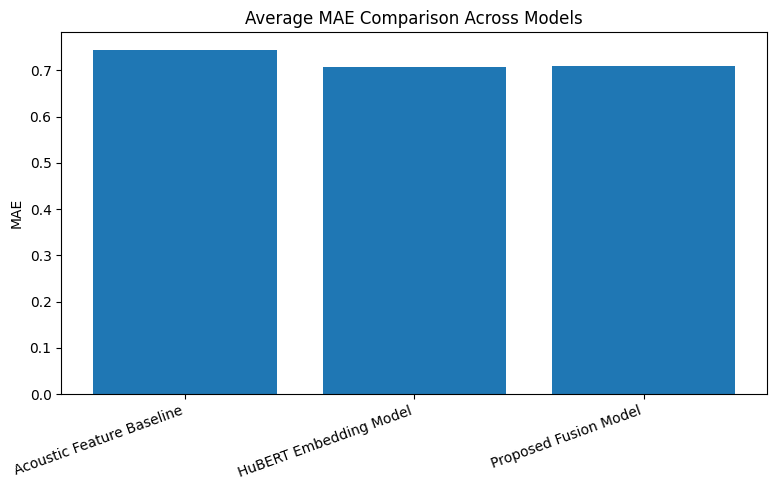

Saved: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/plots/average_mae_comparison.png


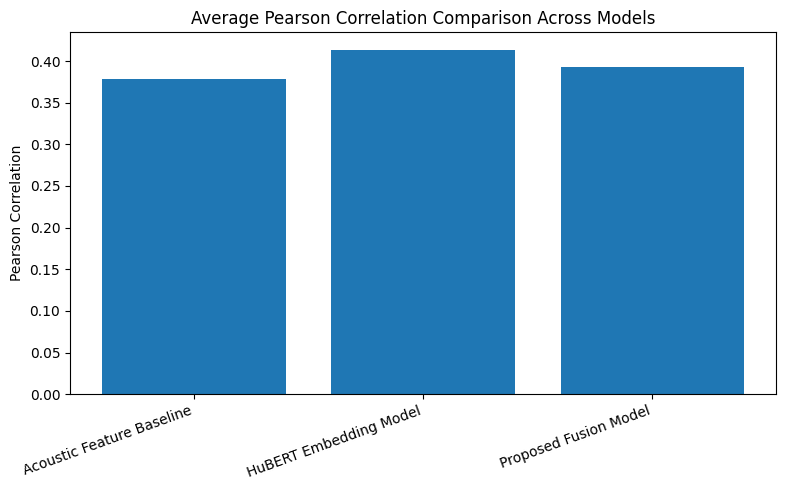

Saved: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/plots/average_pearson_comparison.png


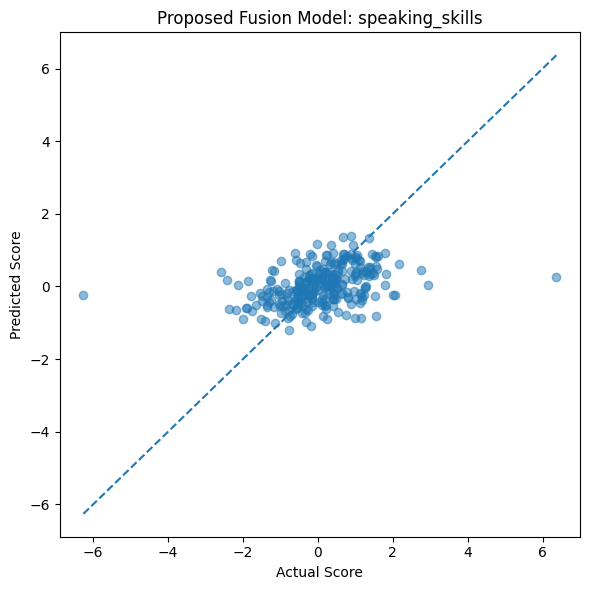

Saved: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/plots/fusion_predicted_vs_actual_speaking_skills.png


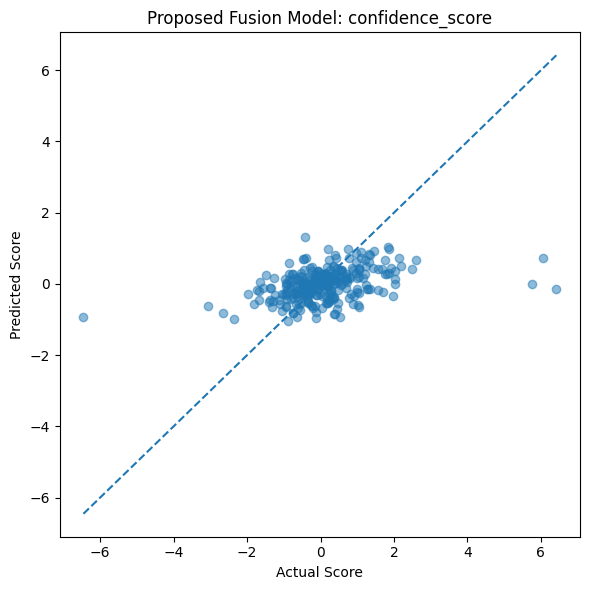

Saved: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/plots/fusion_predicted_vs_actual_confidence_score.png


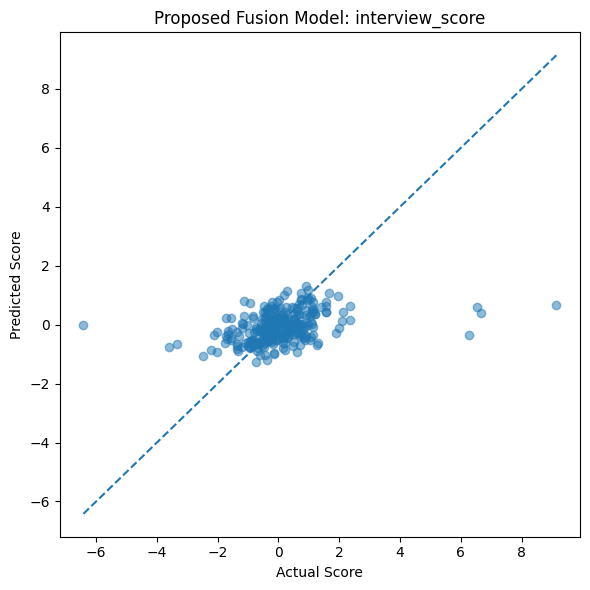

Saved: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/plots/fusion_predicted_vs_actual_interview_score.png


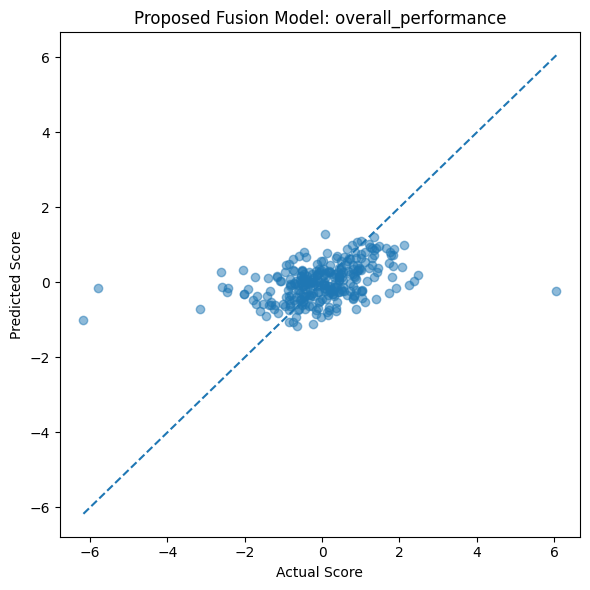

Saved: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/plots/fusion_predicted_vs_actual_overall_performance.png


In [32]:
# Plot MAE comparison
plt.figure(figsize=(8, 5))
plt.bar(average_results_df["model"], average_results_df["MAE"])
plt.ylabel("MAE")
plt.title("Average MAE Comparison Across Models")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

mae_plot_path = PLOTS_DIR / "average_mae_comparison.png"
plt.savefig(mae_plot_path, dpi=300)

plt.show()

print("Saved:", mae_plot_path)

# Plot pearson comparision
plt.figure(figsize=(8, 5))
plt.bar(average_results_df["model"], average_results_df["Pearson"])
plt.ylabel("Pearson Correlation")
plt.title("Average Pearson Correlation Comparison Across Models")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

pearson_plot_path = PLOTS_DIR / "average_pearson_comparison.png"
plt.savefig(pearson_plot_path, dpi=300)

plt.show()

print("Saved:", pearson_plot_path)

# Plot prediction vs actual for proposed model

for target_index, target_name in enumerate(TARGET_COLUMNS):
    plt.figure(figsize=(6, 6))

    plt.scatter(
        y_true_fusion[:, target_index],
        y_pred_fusion[:, target_index],
        alpha=0.5,
    )

    min_value = min(y_true_fusion[:, target_index].min(), y_pred_fusion[:, target_index].min())
    max_value = max(y_true_fusion[:, target_index].max(), y_pred_fusion[:, target_index].max())

    plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

    plt.xlabel("Actual Score")
    plt.ylabel("Predicted Score")
    plt.title(f"Proposed Fusion Model: {target_name}")

    plt.tight_layout()

    plot_path = PLOTS_DIR / f"fusion_predicted_vs_actual_{target_name}.png"
    plt.savefig(plot_path, dpi=300)

    plt.show()

    print("Saved:", plot_path)

## Best model for agent input

In [33]:
# For the agentic layer, we use the proposed fusion model predictions.
# These are already computed in previous cells:
# y_true_fusion
# y_pred_fusion
# test_embedding_paths

print("Using Proposed Fusion Model as final prediction layer.")
print("Number of test predictions:", len(y_pred_fusion))
print("Targets:", TARGET_COLUMNS)

Using Proposed Fusion Model as final prediction layer.
Number of test predictions: 279
Targets: ['speaking_skills', 'confidence_score', 'interview_score', 'overall_performance']


In [34]:
# build final prediction dataframe for agentic layer
agent_output_dir = PROJECT_ROOT / "outputs" / "agent_inputs"
agent_output_dir.mkdir(parents=True, exist_ok=True)

# Base metadata for the test samples used in embedding extraction
test_metadata_for_agents = test_df.set_index("audio_path").loc[test_embedding_paths].reset_index()

# Acoustic features for the same test samples
test_acoustic_for_agents = acoustic_df.set_index("audio_path").loc[test_embedding_paths].reset_index()

agent_predictions_df = pd.DataFrame()

# Keep useful identifiers
if "id" in test_metadata_for_agents.columns:
    agent_predictions_df["id"] = test_metadata_for_agents["id"].values

if "user_no" in test_metadata_for_agents.columns:
    agent_predictions_df["user_no"] = test_metadata_for_agents["user_no"].values

if "question_id" in test_metadata_for_agents.columns:
    agent_predictions_df["question_id"] = test_metadata_for_agents["question_id"].values

if "question" in test_metadata_for_agents.columns:
    agent_predictions_df["question"] = test_metadata_for_agents["question"].values

agent_predictions_df["audio_path"] = test_embedding_paths

# Add actual and predicted scores
for index, target in enumerate(TARGET_COLUMNS):
    agent_predictions_df[f"actual_{target}"] = y_true_fusion[:, index]
    agent_predictions_df[f"predicted_{target}"] = y_pred_fusion[:, index]

# Add acoustic indicators useful for feedback agents
agent_acoustic_columns = [
    "duration_sec",
    "pause_ratio",
    "voiced_ratio",
    "speaking_rate",
    "energy_mean",
    "energy_std",
    "pitch_mean",
    "pitch_std",
]

for column in agent_acoustic_columns:
    if column in test_acoustic_for_agents.columns:
        agent_predictions_df[column] = test_acoustic_for_agents[column].values

# Optional: transcript can help the agent give content-aware feedback later
# For now, keep it if available, but the DL model itself remains audio-only.
if "transcript" in test_metadata_for_agents.columns:
    agent_predictions_df["transcript"] = test_metadata_for_agents["transcript"].fillna("").values

agent_predictions_df.head()

,id,user_no,question_id,question,audio_path,actual_speaking_skills,predicted_speaking_skills,actual_confidence_score,predicted_confidence_score,actual_interview_score,...,predicted_overall_performance,duration_sec,pause_ratio,voiced_ratio,speaking_rate,energy_mean,energy_std,pitch_mean,pitch_std,transcript
0,7,57,1,Introduce yourself,data/processed/audio_wav/vid_0007.wav,-0.240340,0.234624,0.131571,0.270852,0.034531,...,0.252370,22.544750,0.079486,0.920514,199.603012,0.016069,0.015563,126.185151,12.796805,[00:01 - 00:04] Hello and a very good evening ...
1,10,101,1,Introduce yourself,data/processed/audio_wav/vid_0010.wav,-1.049752,-0.493435,-0.812367,-0.418118,-0.835520,...,-0.436203,25.627188,0.220827,0.779173,170.912239,0.039288,0.034276,125.586635,30.843425,[00:00 - 00:03] My name is Ikaagar Agarwal and...
2,17,323,1,Introduce yourself,data/processed/audio_wav/vid_0017.wav,-1.039841,-0.136229,-0.197668,-0.027078,-0.717421,...,0.004455,26.123500,0.191533,0.808467,124.026260,0.039985,0.037681,136.725230,66.358462,"[00:01 - 00:12] Good morning, my name is Shiva..."
3,18,295,1,Introduce yourself,data/processed/audio_wav/vid_0018.wav,0.197782,0.193347,0.473713,0.060732,0.581900,...,0.148525,17.346375,0.319281,0.680719,145.275310,0.112075,0.098025,157.972420,20.467663,[00:00 - 00:07] My name is Aasthika Adarsh. I ...
4,19,180,1,Introduce yourself,data/processed/audio_wav/vid_0019.wav,-1.099504,-0.061853,-0.331250,-0.026387,-0.598522,...,-0.166141,50.312937,0.155366,0.844634,137.141665,0.027689,0.023862,251.896863,165.294820,"[00:00 - 00:04] Hello, my name is Priyal Jain...."


In [35]:
agent_csv_path = agent_output_dir / "test_predictions_for_agents.csv"
agent_json_path = agent_output_dir / "test_predictions_for_agents.json"

agent_predictions_df.to_csv(agent_csv_path, index=False)

agent_predictions_records = agent_predictions_df.to_dict(orient="records")

with open(agent_json_path, "w", encoding="utf-8") as file:
    json.dump(agent_predictions_records, file, indent=4)

print("Saved agent CSV input to:", agent_csv_path)
print("Saved agent JSON input to:", agent_json_path)
print("Rows:", len(agent_predictions_df))

Saved agent CSV input to: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/agent_inputs/test_predictions_for_agents.csv
Saved agent JSON input to: /Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/agent_inputs/test_predictions_for_agents.json
Rows: 279


In [37]:
# ============================================================
# Schema-compatible agent input export
# ============================================================
# This cell converts the notebook prediction output into the
# JSON structure expected by the existing agentic layer schema.
#
# Expected schema:
# {
#   "sample_id": "...",
#   "question": "...",
#   "transcript": "...",
#   "predictions": {
#       "speaking_skills": 0.0-1.0,
#       "confidence_score": 0.0-1.0,
#       "interview_score": 0.0-1.0,
#       "overall_performance": 0.0-1.0,
#       "answer_score": null
#   },
#   "acoustic_features": {
#       "duration_sec": ...,
#       "speaking_rate_wpm": ...,
#       "pause_count": null,
#       "long_pause_count": null,
#       "pause_ratio": ...,
#       "mean_pitch": ...,
#       "pitch_variation": ...,
#       "mean_energy": ...
#   }
# }

agent_output_dir = PROJECT_ROOT / "outputs" / "agent_inputs"
agent_output_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Select final prediction model for agent layer
# ------------------------------------------------------------
# Since HuBERT embedding model gave the best overall result,
# we use it as the final prediction layer.
#
# If you want to use fusion model instead, replace:
# y_pred_final = y_pred_embedding
# with:
# y_pred_final = y_pred_fusion

y_pred_final = y_pred_embedding
final_prediction_paths = test_embedding_paths

print("Using HuBERT Embedding Model predictions for agent input.")
print("Number of predictions:", len(y_pred_final))

Using HuBERT Embedding Model predictions for agent input.
Number of predictions: 279


In [38]:
# ============================================================
# Normalize predicted scores to 0-1 for schema compatibility
# ============================================================

target_min = train_df[TARGET_COLUMNS].min()
target_max = train_df[TARGET_COLUMNS].max()

def normalize_score_to_0_1(value, target_name):
    """
    Convert original dataset score scale into 0-1 range.
    Values outside the training range are clipped.
    """

    min_value = target_min[target_name]
    max_value = target_max[target_name]

    if max_value == min_value:
        return None

    normalized = (value - min_value) / (max_value - min_value)
    normalized = float(np.clip(normalized, 0.0, 1.0))

    return normalized

In [39]:
# ============================================================
# Build schema-compatible records
# ============================================================

# Metadata for the same test samples used during embedding extraction
test_metadata_for_agents = test_df.set_index("audio_path").loc[final_prediction_paths].reset_index()

# Acoustic features for the same samples
test_acoustic_for_agents = acoustic_df.set_index("audio_path").loc[final_prediction_paths].reset_index()

schema_records = []

for i in range(len(test_metadata_for_agents)):
    metadata_row = test_metadata_for_agents.iloc[i]
    acoustic_row = test_acoustic_for_agents.iloc[i]

    # Sample ID
    if "id" in metadata_row:
        sample_id = str(metadata_row["id"])
    else:
        sample_id = str(i)

    # Question
    question = metadata_row["question"] if "question" in metadata_row and pd.notna(metadata_row["question"]) else ""

    # Transcript
    transcript = metadata_row["transcript"] if "transcript" in metadata_row and pd.notna(metadata_row["transcript"]) else ""

    # Predictions in schema format
    predictions = {
        "speaking_skills": normalize_score_to_0_1(
            y_pred_final[i][TARGET_COLUMNS.index("speaking_skills")],
            "speaking_skills",
        ),
        "confidence_score": normalize_score_to_0_1(
            y_pred_final[i][TARGET_COLUMNS.index("confidence_score")],
            "confidence_score",
        ),
        "interview_score": normalize_score_to_0_1(
            y_pred_final[i][TARGET_COLUMNS.index("interview_score")],
            "interview_score",
        ),
        "overall_performance": normalize_score_to_0_1(
            y_pred_final[i][TARGET_COLUMNS.index("overall_performance")],
            "overall_performance",
        ),
        "answer_score": None,
    }

    # Acoustic features in schema format
    acoustic_features = {
        "duration_sec": float(acoustic_row["duration_sec"]) if "duration_sec" in acoustic_row else None,
        "speaking_rate_wpm": float(acoustic_row["speaking_rate"]) if "speaking_rate" in acoustic_row else None,
        "pause_count": None,
        "long_pause_count": None,
        "pause_ratio": float(acoustic_row["pause_ratio"]) if "pause_ratio" in acoustic_row else None,
        "mean_pitch": float(acoustic_row["pitch_mean"]) if "pitch_mean" in acoustic_row else None,
        "pitch_variation": float(acoustic_row["pitch_std"]) if "pitch_std" in acoustic_row else None,
        "mean_energy": float(acoustic_row["energy_mean"]) if "energy_mean" in acoustic_row else None,
    }

    record = {
        "sample_id": sample_id,
        "question": question,
        "transcript": transcript,
        "predictions": predictions,
        "acoustic_features": acoustic_features,
    }

    schema_records.append(record)

print("Schema-compatible records created:", len(schema_records))
schema_records[0]

Schema-compatible records created: 279


{'sample_id': '7',
 'question': 'Introduce yourself',
 'transcript': '[00:01 - 00:04] Hello and a very good evening to whomever it may concern.\n[00:04 - 00:11] My name is Avaril Sanjay Gupta and I am currently pursuing my Bachelors in Technology from Manipal University, Japan.\n[00:11 - 00:14] I was born and brought up in Hindu, Egypter Pradesh.\n[00:14 - 00:20] I am a passionate tech enthusiast and my main interests are artificial intelligence, machine learning and web development.\n[00:20 - 00:21] Thank you.',
 'predictions': {'speaking_skills': 0.5619446664195799,
  'confidence_score': 0.5282965829891547,
  'interview_score': 0.4333912371561387,
  'overall_performance': 0.5285320306584119,
  'answer_score': None},
 'acoustic_features': {'duration_sec': 22.54475,
  'speaking_rate_wpm': 199.60301178766676,
  'pause_count': None,
  'long_pause_count': None,
  'pause_ratio': 0.0794863549163331,
  'mean_pitch': 126.18515071486236,
  'pitch_variation': 12.796805323182287,
  'mean_energy'

In [42]:
# ============================================================
# Select demo samples for the agentic feedback layer
# ============================================================

def get_overall_score(record):
    score = record["predictions"]["overall_performance"]
    return score if score is not None else 0.0


sorted_records = sorted(schema_records, key=get_overall_score)

weak_sample = sorted_records[0]
strong_sample = sorted_records[-1]

demo_records = [weak_sample, strong_sample]

print("Selected demo samples:")
for record in demo_records:
    print(
        "sample_id:",
        record["sample_id"],
        "| question:",
        record["question"],
        "| predicted overall:",
        record["predictions"]["overall_performance"],
    )

Selected demo samples:
sample_id: 144 | question: Introduce yourself | predicted overall: 0.42444601688908634
sample_id: 1901 | question: What are your weaknesses? | predicted overall: 0.6311116460796209


In [43]:
# ============================================================
# Save schema-compatible JSON files
# ============================================================

single_demo_path = agent_output_dir / "demo_agent_input.json"
two_sample_demo_path = agent_output_dir / "demo_agent_inputs.json"
full_schema_output_path = agent_output_dir / "all_test_agent_inputs_schema.json"

# Save one sample only, compatible with the old example file style
with open(single_demo_path, "w", encoding="utf-8") as file:
    json.dump(weak_sample, file, indent=4)

# Save two demo samples as a list
with open(two_sample_demo_path, "w", encoding="utf-8") as file:
    json.dump(demo_records, file, indent=4)

# Optional: save all test samples in schema-compatible format
with open(full_schema_output_path, "w", encoding="utf-8") as file:
    json.dump(schema_records, file, indent=4)

print("Saved single demo input:")
print(single_demo_path)

print("\nSaved two-sample demo input:")
print(two_sample_demo_path)

print("\nSaved full schema-compatible test input:")
print(full_schema_output_path)

Saved single demo input:
/Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/agent_inputs/demo_agent_input.json

Saved two-sample demo input:
/Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/agent_inputs/demo_agent_inputs.json

Saved full schema-compatible test input:
/Users/charvisri/Desktop/BTH/DL/Final Project/Voice-Interview-Agent/outputs/agent_inputs/all_test_agent_inputs_schema.json
